In [1]:
import math
pi = math.pi
import matplotlib.pyplot as plt
import numpy as np
import sys
# Suppress warnings
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
import matplotlib
# Integration
import scipy.integrate as integrate
# Special functions
import scipy.special as special

In [2]:
from matplotlib.ticker import AutoMinorLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import sympy as sp
from scipy.optimize import fsolve
matplotlib.rcParams.update({'text.usetex': True})
plt.rcParams.update({
       "text.usetex": True,
       "font.family": "serif",
       "font.size": 16,
       "axes.labelsize": 16,
       "axes.titlesize": 16,
       "legend.fontsize": 14,
       "xtick.labelsize": 14,
       "ytick.labelsize": 14,
})

### Quantum Dots' Parametrs

$ɛ = 1$ On-site mean local energy

$ɛ_L = ɛ + \frac{1}{2}δ$ On-site mean left energy

$ɛ_R = ɛ - \frac{1}{2}δ$ On-site mean right energy

$δ = 0.0$ detuning

$g =0.5$ coupling strength


$Δ=\sqrt{δ^2+g^2}$

$Ω=100$ Intra-reservoir tunnelling energy/hopping amplitude


In [3]:
# Quantum Dots' Parametrs
eps = 1.0 # on-site mean local energy
delta = 1.0
eps_L = eps + 0.5 * delta
eps_R = eps - 0.5 * delta
g = 0.5 # coupling strength
Delta  = np.sqrt(delta**2 + g**2)
Gamma = 2e-2 # the overall frequency scale of the dissipative dynamics
Omega = 100.0 # intra-reservoir tunnelling energy/hopping amplitude

### Basis Energies

$E_1 = ɛ+ \frac{Δ}{2}$

$E_1 = ɛ- \frac{Δ}{2}$

In [4]:
# Basis Energies
E1 = eps + 0.5*Delta
E2 = eps - 0.5*Delta

### Reservoirs' parameters


<!-- $T=0.3\varepsilon$ -->

$\mu_L = \varepsilon_L+\varepsilon_R$ Electrochemical potential of the left reservoir

$\mu_R = 0.0$ Electrochemical potential of the right reservoir

In [5]:
# Reservoirs' parameters
T = np.linspace(2e-2, 2e-0, 301)
muL = 0.7
muR = 0.0

### Fermi-Dirac fucntion

\begin{equation*}
f(\omega) = \frac{1}{e^{β(\omega-\mu)}+1}
\end{equation*}


In [6]:
# Dimensionless Fermi-Dirac fucntion expressed with reduced variable x=beta*(E-mu)
f = lambda x: 1./(1. + np.exp(x))

### Spectral density

\begin{align*}
\mathcal{J}_N(\omega) = \frac{\Gamma}{2\pi} \sqrt{1 - \frac{\omega^2}{\Omega^2}} \, \Theta(\Omega - |\omega|)
\end{align*}
### Propability Destribution of Excitation Energy

\begin{align*}
\varphi_j(\omega)=\frac{1}{1-\Gamma / \Omega} \frac{\mathcal{J}_{\mathrm{N}}(\omega)}{\left(\omega-E_j^{\prime}\right)^2+\Gamma_j^2 / 4}
\end{align*}
### Shifted Energies and Decay Rates

\begin{align*}
E'_j = \frac{1 - \Gamma / 2\Omega}{1 - \Gamma / \Omega} E_j, \quad
\Gamma_j = \frac{\sqrt{1 - \Gamma / \Omega - E_j^2 / \Omega^2}}{1 - \Gamma / \Omega} \Gamma.
\end{align*}
### Transmission function

\begin{align*}
\mathcal{T}(\omega)=\frac{\pi g^2}{2} \varphi_1(\omega) \varphi_2(\omega)
\end{align*}

### Uder Exponential-propagator approximation (EPA)

\begin{align*}
E'_j \approx E_j, \quad
\Gamma_j = \frac{\sqrt{1 - \Gamma / \Omega - E_j^2 / \Omega^2}}{1 - \Gamma / \Omega} \Gamma  \approx 2 \pi \mathcal{J}_N(E_j).
\end{align*}

In [7]:
# Spectral density
def J(omega, Gamma, Omega):
     return Gamma/(2.0*np.pi)*np.sqrt(1.0-omega**2/Omega**2)*np.heaviside(Omega-abs(omega),0)
#  Probability distribution of excitation energy
def phi(omega, Gamma, Omega, E):
    E_dash = E
    Gamma_dash = 2.0*np.pi*J(E_dash, Gamma, Omega)
    return 1.0/((omega-E_dash)**2+(Gamma_dash/2.0)**2)*J(omega, Gamma, Omega)
# Trasnmission function
def Tau(omega, Gamma, Omega, E1, E2, g):
    return np.pi*g**2/2.0*phi(omega, Gamma, Omega, E1)*phi(omega, Gamma, Omega, E2)
# Gamma j
Gamma_function = lambda Gamma, Omega, E: (2.0*np.pi*J(E, Gamma, Omega))
# Current
def dI(omega, Gamma, Omega, E1, E2, g, T, muL, muR):
     return Tau(omega, Gamma, Omega, E1, E2, g)*(f((omega-muL)/T)-f((omega-muR)/T))
#Noise
def dS(omega, Gamma, Omega, E1, E2, g, T, muL, muR):
     return Tau(omega, Gamma, Omega, E1, E2, g)*(f((omega-muL)/T)+f((omega-muR)/T)-2.0*f((omega-muL)/T)*f((omega-muR)/T)-Tau(omega, Gamma, Omega, E1, E2, g)*(f((omega-muL)/T)-f((omega-muR)/T))**2)

### Average Steady-State Current

\begin{equation*}
    J_L = \int_{-\infty}^{\infty}  \mathcal{T}(\omega)[f_L(\omega)-f_R(\omega)] d\omega
\end{equation*}

In [8]:
# Integration: <J>
I_avg = np.zeros(np.size(T)) 
for i in range(np.size(T)): 
  I_avg[i] = integrate.quad(dI,-Omega,Omega,args=(Gamma, Omega, E1, E2, g, T[i], muL, muR), points = [E1, E2], epsabs=1.49e-10,epsrel=1.49e-20)[0]

### Current Fluctuations

\begin{equation*}
    D_L = \int_{-\infty}^{\infty}  \mathcal{T}(\omega) \{ [f_L(\omega)+f_R(\omega)-2f_L(\omega)f_R(\omega)]-\mathcal{T}(\omega)[f_L(\omega)-f_R(\omega)]^2\}
    d\omega
\end{equation*}

In [9]:
# Integration: <<J^2>>
I_I = np.zeros(np.size(T))
for i in range(np.size(T)): 
   I_I[i] = integrate.quad(dS,-Omega,Omega,args=(Gamma, Omega, E1, E2, g, T[i], muL, muR), points = [E1, E2], epsabs=1.49e-10,epsrel=1.49e-20)[0]

### Master Eqaution

In [10]:
# #Functions for Current, Flcutuations
def Vectorize_Mat (M):
    return Qobj(np.concatenate([M[:, i:i+1] for i in range(M.shape[1])], axis=0))
#Inputs: LList: list of jump operators; NuList: list of jump coefficients (e.g. +1 and -1 for particle current jumps)
def JJ(LList, NuList):
    result = Qobj(np.zeros(tensor([LList[0].conj(), LList[0]]).shape))
    for i in range(len(NuList)):
        result +=  NuList[i]*Qobj(tensor([LList[i].conj(), LList[i]]),dims=tensor([LList[0].conj(), LList[0]]).shape)
    return result
#Inputs: sst: steady state as qutip object; JJj: Jump operators from above
def Current(sst,JJj):
    N_sst=sst.shape[0]
    id = Vectorize_Mat(qeye(N_sst))
    return(np.real(id.dag()*JJj*Vectorize_Mat(sst)))
##Inputs: Lbb: Lindbladian in qutip format; steadys: steady state in qutip format
# JJ2: the jump operator with all elements in NuList equal to 1; JJ: the jump operator
def Noise(Lbb, steadys, JJ2, JJ):
    N_sst=steadys.shape[0]
    vectsteady=Vectorize_Mat(steadys)
    I2L = Vectorize_Mat(qeye(N_sst)).dag()
    # Calculate the expression using NumPy operations
    alpha=JJ*vectsteady
    A=np.vstack((Lbb.full(),I2L.full()))
    B=np.vstack(((alpha - vectsteady*I2L*alpha).full(),0))
    z= Qobj(np.linalg.lstsq(A,B,rcond=None)[0])
    K=I2L*JJ2*vectsteady
    result = K-2*I2L*JJ*z
    return np.real(result)

In [11]:
from qutip import *
# Creation and annihilation operators for N quantum dots: Define operators for each quantum dot
N = 2
def fermion_annihilation(N, i):
    """
    Fermionic annihilation operator at site i using Jordan-Wigner transformation.

    Parameters:
    - N: total number of sites
    - i: site index (0-based)

    Returns:
    - Qobj: fermionic annihilation operator c_i
    """
    if not (0 <= i < N):
        raise ValueError("Index i must be between 0 and N-1")

    op_list = [sigmaz() for _ in range(i)]          # σ_z^⊗i
    op_list.append(sigmam())                        # σ_-
    op_list.extend([qeye(2) for _ in range(N - i - 1)])  # I^⊗(N-i-1)

    return tensor(op_list)

c0 = fermion_annihilation(N, 0)
c1 = fermion_annihilation(N, 1)

In [12]:
H_sys = eps_L * c0.dag()*c0 + eps_R * c1.dag()*c1
H_sys -= 0.5 * g * (c0.dag() * c1 + c1.dag() * c0)

### Non-additivity in the local basis

### Orthogonal Rotation Matrix

\begin{equation*}
R = \frac{1}{\sqrt{2\Delta}}
\left(
\begin{array}{cc}
\sqrt{\Delta + \delta} & -\sqrt{\Delta - \delta} \\ \sqrt{\Delta - \delta} & \sqrt{\Delta + \delta}
\end{array}
\right)
\end{equation*}

In [13]:
# Orthogonal rotation matrix
R = 1.0/np.sqrt(2 * Delta) * np.array([[np.sqrt(Delta+delta), -np.sqrt(Delta-delta)],[np.sqrt(Delta-delta), np.sqrt(Delta+delta)]])

### Decay Rates

\begin{align*}
\Gamma_j = \frac{\sqrt{1 - \Gamma / \Omega - E_j^2 / \Omega^2}}{1 - \Gamma / \Omega} \Gamma \approx 2 \pi \mathcal{J}_N(E_j)
\end{align*}

### Gammas
$ \Gamma_{L,j}= \Gamma_{j}R_{1j}^2$

$ \Gamma_{R,j}= \Gamma_{j}R_{2j}^2$

$j=1,2$

In [14]:
# Gamma_L,1
GammaL1 = Gamma_function(Gamma, Omega, E1) * R[0,0]**2
# Gamma_L,2
GammaL2 = Gamma_function(Gamma, Omega, E2) * R[0,1]**2
# Gamma_R,1
GammaR1 = Gamma_function(Gamma, Omega, E1) * R[1,0]**2
# Gamma_R,1
GammaR2 = Gamma_function(Gamma, Omega, E2) * R[1,1]**2

In [15]:
# Decay and gain rates
def dg_m(omega, Gamma, Omega, E, mu, T):
  return phi(omega, Gamma, Omega, E) * (1.0 - f((omega-mu)/T))
def dg_p(omega, Gamma, Omega, E, mu, T):
  return phi(omega, Gamma, Omega, E) * f((omega-mu)/T)

### Deacay and Gian Rates

\begin{align*}
\gamma_{\alpha, j}^{-}=\Gamma_{\alpha, j} \int \mathrm{~d} \omega \ \varphi_j(\omega)[1-f_{α}(ω)] \\
\gamma_{\alpha, j}^{+}=\Gamma_{\alpha, j} \int \mathrm{~d} \omega \ \varphi_j(\omega)f_{α}(ω) \\
\end{align*}




In [16]:
# Decay and gain rates
gammaL1_m, gammaR1_m, gammaL2_m, gammaR2_m = np.zeros(np.size(T)), np.zeros_like(T), np.zeros_like(T),np.zeros_like(T)
gammaL1_p, gammaR1_p, gammaL2_p, gammaR2_p = np.zeros_like(T), np.zeros_like(T), np.zeros_like(T),np.zeros_like(T)
for i in range(np.size(T)): 
  gammaL1_m[i] = integrate.quad(dg_m,-Omega,Omega,args=(Gamma, Omega, E1, muL, T[i]), points = [E1], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaR1_m[i] = integrate.quad(dg_m,-Omega,Omega,args=(Gamma, Omega, E1, muR, T[i]), points = [E1], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaL2_m[i] = integrate.quad(dg_m,-Omega,Omega,args=(Gamma, Omega, E2, muL, T[i]), points = [E2], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaR2_m[i] = integrate.quad(dg_m,-Omega,Omega,args=(Gamma, Omega, E2, muR, T[i]), points = [E2], epsabs=1.49e-8,epsrel=1.49e-12)[0]

  gammaL1_p[i] = integrate.quad(dg_p,-Omega,Omega,args=(Gamma, Omega, E1, muL, T[i]), points = [E1], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaR1_p[i] = integrate.quad(dg_p,-Omega,Omega,args=(Gamma, Omega, E1, muR, T[i]), points = [E1], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaL2_p[i] = integrate.quad(dg_p,-Omega,Omega,args=(Gamma, Omega, E2, muL, T[i]), points = [E2], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  gammaR2_p[i] = integrate.quad(dg_p,-Omega,Omega,args=(Gamma, Omega, E2, muR, T[i]), points = [E2], epsabs=1.49e-8,epsrel=1.49e-12)[0]


In [17]:
gammaL1_m *= GammaL1
gammaR1_m *= GammaR1
gammaL2_m *= GammaL2
gammaR2_m *= GammaR2

gammaL1_p *= GammaL1
gammaR1_p *= GammaR1
gammaL2_p *= GammaL2
gammaR2_p *= GammaR2

### Non-additive Rates
$\overline{γ}^{\pm}_{\alpha} = {γ}^{\pm}_{1,\alpha} + {γ}^{\pm}_{2,\alpha}$


In [18]:
# Dash rates
gammaL_m_dash = (gammaL1_m + gammaL2_m)
gammaR_m_dash = (gammaR1_m + gammaR2_m)
gammaL_p_dash = (gammaL1_p + gammaL2_p)
gammaR_p_dash = (gammaR1_p + gammaR2_p)

### Delocalised Lindblad Dissipators

\begin{equation*}
\bar{\mathcal{L}}_{LR} \hat{\rho}_S = \sum_{\alpha \neq \alpha'} \left[ \bar{\Lambda}_{\alpha \alpha'}^+ \left( \hat{c}_{\alpha'}^\dagger  \hat{\rho}_S \hat{c}_\alpha - \frac{1}{2} \{ \hat{c}_\alpha \hat{c}_{\alpha'}^\dagger, \hat{\rho }_S \} \right) + \bar{\Lambda}_{\alpha \alpha'}^- \left( \hat{c}_{\alpha} \hat{\rho }_S \hat{c}_{\alpha'}^\dagger - \frac{1}{2} \{ \hat{c}_{\alpha'}^\dagger \hat{c}_\alpha, \hat{\rho }_S \} \right) \right]
\end{equation*}

\begin{equation*}
{\bar{\Lambda}}_{LR}^{\pm}=({\bar{\Lambda}}_{RL}^{\pm})^*
\end{equation*}

In [19]:
# Lamda LR PM matrix: Re and Im parts
def dLambda_dash_p_re(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return (Gamma_function(Gamma, Omega, E2)*phi(omega, Gamma, Omega, E2)-Gamma_function(Gamma, Omega, E1)*phi(omega, Gamma, Omega, E1))*(f((omega-muL)/T)+f((omega-muR)/T))
def dLambda_dash_p_im(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return ((E1-omega)*phi(omega, Gamma, Omega, E1)-(E2-omega)*phi(omega, Gamma, Omega, E2))*(f((omega-muL)/T)-f((omega-muR)/T))
def dLambda_dash_m_re(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return (Gamma_function(Gamma, Omega, E2)*phi(omega, Gamma, Omega, E2)-Gamma_function(Gamma, Omega, E1)*phi(omega, Gamma, Omega, E1))*(2.0 - f((omega-muL)/T)-f((omega-muR)/T))

### Re and Im Parts

\begin{align*}
\text{Re} [\bar{\Lambda}^{+}_{LR}] &= \frac{g}{4\Delta} \int d\omega \left[ \Gamma_2 \varphi_2(\omega) - \Gamma_1 \varphi_1(\omega) \right] \left[ f_L(\omega) + f_R(\omega) \right], \\
\text{Im} [\bar{\Lambda}^{+}_{LR}] &= \frac{g}{2\Delta} \int d\omega \left[ (E_1 - \omega) \varphi_1(\omega) - (E_2 - \omega) \varphi_2(\omega) \right] \left[ f_L(\omega) - f_R(\omega) \right], \\
\text{Re} [\bar{\Lambda}^{-}_{LR}] &= \frac{g}{4\Delta} \int d\omega \left[ \Gamma_2 \varphi_2(\omega) - \Gamma_1 \varphi_1(\omega) \right] \left[ 2 - f_L(\omega) - f_R(\omega) \right], \\
\text{Im} [\bar{\Lambda}^{-}_{LR}] &= -\text{Im} [\bar{\Lambda}^{+}_{LR}].
\end{align*}

In [20]:
# Lamda LR PM matrix: Re and Im parts
Lambda_dash_p_re, Lambda_dash_p_im, Lambda_dash_m_re, Lambda_dash_m_im = np.zeros(np.size(T)), np.zeros(np.size(T)), np.zeros(np.size(T)),np.zeros(np.size(T))
for i in range(np.size(T)):
  Lambda_dash_p_re[i] = integrate.quad(dLambda_dash_p_re,-Omega,Omega,args=(Gamma, Omega, E1, E2, muL, muR, T[i]), points = [E1, E2], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  Lambda_dash_p_im[i] = integrate.quad(dLambda_dash_p_im,-Omega,Omega,args=(Gamma, Omega, E1, E2, muL, muR, T[i]), points = [E1, E2], epsabs=1.49e-8,epsrel=1.49e-12)[0]
  Lambda_dash_m_re[i] = integrate.quad(dLambda_dash_m_re,-Omega,Omega,args=(Gamma, Omega, E1, E2, muL, muR, T[i]), points = [E1, E2], epsabs=1.49e-8,epsrel=1.49e-12)[0]

In [21]:
# Lamda LR PM matrix: Re and Im parts
Lambda_dash_p_re *= g/(4*Delta)
Lambda_dash_p_im *= g/(2*Delta)
Lambda_dash_m_re *= g/(4*Delta)
Lambda_dash_m_im = - Lambda_dash_p_im

\begin{equation*}
{\bar{\Lambda}}_{LR}^{\pm}= \mathrm{Re}~ {\bar{\Lambda}}_{LR}^{\pm} + \mathrm{i}~ \mathrm{Im}~ {\bar{\Lambda}}_{LR}^{\pm}
\end{equation*}

In [22]:
# Lamda LR PM matrix:
Lambda_dash_p_LR = Lambda_dash_p_re + 1j * Lambda_dash_p_im
Lambda_dash_m_LR = Lambda_dash_m_re + 1j * Lambda_dash_m_im

\begin{equation*}
{\bar{\Lambda}}_{LR}^{\pm}=({\bar{\Lambda}}_{RL}^{\pm})^*
\end{equation*}

In [23]:
# Lamda RL PM matrix:
Lambda_dash_p_RL = Lambda_dash_p_LR.conjugate()
Lambda_dash_m_RL = Lambda_dash_m_LR.conjugate()

###  Total number operator

$\hat{N} = \hat{n}_L+\hat{n}_R$

In [24]:
# Total number operator
N_hat = c1.dag() * c1 + c0.dag() * c0
n_L = c0.dag() * c0

### Local dissipators are Lindblad generators that act only on a single site
$\bar{\mathcal{L}}_\alpha = \bar{\gamma}_\alpha^- \mathcal{D}[\hat{c}_\alpha] + \bar{\gamma}_\alpha^+ \mathcal{D}[\hat{c}_\alpha^\dagger],$
### Average Steady State Current and its Fluctuations

In [25]:
tau = np.logspace(-8, 0, 301) # Time scale for CP test

In [26]:
# Current Noise for Attive and Non-Additive Lindblad Master Equation
I_L, D_L = np.zeros_like(T, dtype = float), np.zeros_like(T, dtype = float)
I_R, D_R = np.zeros_like(T, dtype = float), np.zeros_like(T, dtype = float)
rate_left_plus, rate_left_minus, rate_right_plus, rate_right_minus = np.zeros_like(T, dtype = float), np.zeros_like(T, dtype = float), np.zeros_like(T, dtype = float), np.zeros_like(T, dtype = float)
iscp_test_l0 = np.zeros((np.size(T),np.size(tau)), dtype=bool)
iscp_test_l1 = np.zeros((np.size(T),np.size(tau)), dtype=bool)
np_l = np.zeros((np.size(T),np.size(tau)), dtype=float)
# On-site energies
H_sys = eps_L * c0.dag()*c0 + eps_R * c1.dag()*c1
H_sys -= 0.5 * g * (c0.dag() * c1 + c1.dag() * c0)
for i in range(np.size(T)):
# Non-Lindblad dissipator: general part+anticommutatating term
  D_notLinblad = 0.0
  #LR +
  ad_b = c0 * c1.dag()
  D_notLinblad1 = (spre(c1.dag()) * spost(c0) - 0.5 * spre(ad_b) - 0.5 * spost(ad_b))
  #LR -
  cd_d = c1.dag() * c0
  D_notLinblad2 = (spre(c0) * spost(c1.dag()) - 0.5 * spre(cd_d) - 0.5 * spost(cd_d))
  #RL +
  ed_f = c1 * c0.dag()
  D_notLinblad3 = (spre(c0.dag()) * spost(c1) - 0.5 * spre(ed_f)  - 0.5 * spost(ed_f))
  #RL -
  gd_f = c0.dag()*c1
  D_notLinblad4 = (spre(c1) *spost(c0.dag()) - 0.5 * spre(gd_f) - 0.5 * spost(gd_f))
  D_notLinblad = Lambda_dash_p_LR[i] * D_notLinblad1 + Lambda_dash_m_LR[i] * D_notLinblad2 + Lambda_dash_p_RL[i] * D_notLinblad3 + Lambda_dash_m_RL[i] * D_notLinblad4
  # Left Lindblad part: Colapsed operators
  DL_m = np.sqrt(gammaL_m_dash[i]) * c0
  DL_p = np.sqrt(gammaL_p_dash[i]) * c0.dag()
  # Right Lindblad part: Colapsed operators
  DR_m = np.sqrt(gammaR_m_dash[i]) * c1
  DR_p = np.sqrt(gammaR_p_dash[i]) * c1.dag()
  # Lindblad Liouvillian
  D_Lindblad = liouvillian(H_sys, [DL_m, DL_p, DR_m, DR_p])
  # Full Liouvillian (Non-Lindblad + Lindblad)
  L_total = D_Lindblad + D_notLinblad
  L_L = lindblad_dissipator(DL_p) + lindblad_dissipator(DL_m)
  L_R = lindblad_dissipator(DR_p) + lindblad_dissipator(DR_m)
  L_I = L_L + D_notLinblad + L_R  # Total asymptotic dissipator
  # Find the steady state
  rho_ss_l = steadystate(L_total, method='direct',  return_info=True)
  vector_rho_ss = operator_to_vector(rho_ss_l)

  a = (c0.dag()*vector_to_operator(pseudo_inverse(L_total, method="solve")*operator_to_vector(c0.dag()*rho_ss_l*c0))*c0).tr()
  b = (c0.dag()*vector_to_operator(pseudo_inverse(L_total, method="solve")*operator_to_vector(c0*rho_ss_l*c0.dag()))*c0).tr()
  c = (c0*vector_to_operator(pseudo_inverse(L_total, method="solve")*operator_to_vector(c0.dag()*rho_ss_l*c0))*c0.dag()).tr()
  d = (c0*vector_to_operator(pseudo_inverse(L_total, method="solve")*operator_to_vector(c0*rho_ss_l*c0.dag()))*c0.dag()).tr()
  n_ss = (n_L*rho_ss_l).tr()

  x, y = sp.symbols('x y') #, real=False

  eq1 = sp.Eq(x - (x+y)*n_ss, I_avg[i])  # linear
  eq2 = sp.Eq(x - (x-y)*n_ss -a*x**2+(b+c)*x*y-d*y**2, I_I[i])  # quadratic

  solutions = sp.solve([eq1, eq2], (x, y))
  gamma_plus = np.array([sol[0].evalf(chop=1e-15) for sol in solutions], dtype=complex)  # [1.0, 3.0]
  gamma_minus = np.array([sol[1].evalf(chop=1e-15) for sol in solutions], dtype=complex)  
  L1 = np.sqrt((gamma_plus[0]))* c0.dag()
  L2 = np.sqrt((gamma_minus[0]))* c0
  L3 = np.sqrt((gamma_plus[1]))* c0.dag()
  L4 = np.sqrt((gamma_minus[1]))* c0
  
  I_L[i] = gamma_plus[0] - (gamma_plus[0]+gamma_minus[0])*n_ss
  D_L[i] = gamma_plus[0] - (gamma_plus[0]-gamma_minus[0])*n_ss -a*gamma_plus[0]**2+(b+c)*gamma_plus[0]*gamma_minus[0]-d*gamma_minus[0]**2


  a_0 = (c1.dag()*vector_to_operator(pseudo_inverse(L_total, method="solve")*operator_to_vector(c1.dag()*rho_ss_l*c1))*c1).tr()
  b_0 = (c1.dag()*vector_to_operator(pseudo_inverse(L_total, method="solve")*operator_to_vector(c1*rho_ss_l*c1.dag()))*c1).tr()
  c_0 = (c1*vector_to_operator(pseudo_inverse(L_total, method="solve")*operator_to_vector(c1.dag()*rho_ss_l*c1))*c1.dag()).tr()
  d_0 = (c1*vector_to_operator(pseudo_inverse(L_total, method="solve")*operator_to_vector(c1*rho_ss_l*c1.dag()))*c1.dag()).tr()
  n_rr = (c1.dag()*c1*rho_ss_l).tr()

  z, t = sp.symbols('z t') #, real=False

  eq = sp.Eq(z - (z+t)*n_rr, -I_avg[i])  # linear
  eq0 = sp.Eq(z - (z-t)*n_rr -a_0*z**2+(b_0+c_0)*z*t-d_0*t**2, I_I[i])  # quadratic

  results = sp.solve([eq, eq0], (z, t))
  z_vals = np.array([sol[0].evalf(chop=1e-15) for sol in results], dtype=complex)  # [1.0, 3.0]
  t_vals = np.array([sol[1].evalf(chop=1e-15) for sol in results], dtype=complex)  
  M1 = np.sqrt((z_vals[0]))* c1.dag()
  M2 = np.sqrt((t_vals[0]))* c1
  M3 = np.sqrt((z_vals[1]))* c1.dag()
  M4 = np.sqrt((t_vals[1]))* c1

  rate_left_plus[i] = np.real(gamma_plus[0])
  rate_left_minus[i] = np.real(gamma_minus[0])
  rate_right_plus[i] = np.real(z_vals[0])
  rate_right_minus[i] = np.real(t_vals[0])

  I_R[i] = z_vals[0] - (z_vals[0]+t_vals[0])*n_rr
  D_R[i] = z_vals[0] - (z_vals[0]-t_vals[0])*n_rr -a_0*z_vals[0]**2+(b_0+c_0)*z_vals[0]*t_vals[0]-d_0*t_vals[0]**2  

  # Testing Complete positivity
  for j in range(np.size(tau)):
    t = tau[j] # time interval
    J0 = (t*(L_total - sum(sprepost(L, L.dag()) for L in [L1, L2, M1, M2]))).expm() 
    J1 = (t*(L_total - sum(sprepost(L, L.dag()) for L in [L3, L4, M3, M4]))).expm()
    iscp_test_l0[i,j] = J0.iscp
    iscp_test_l1[i,j] = J1.iscp

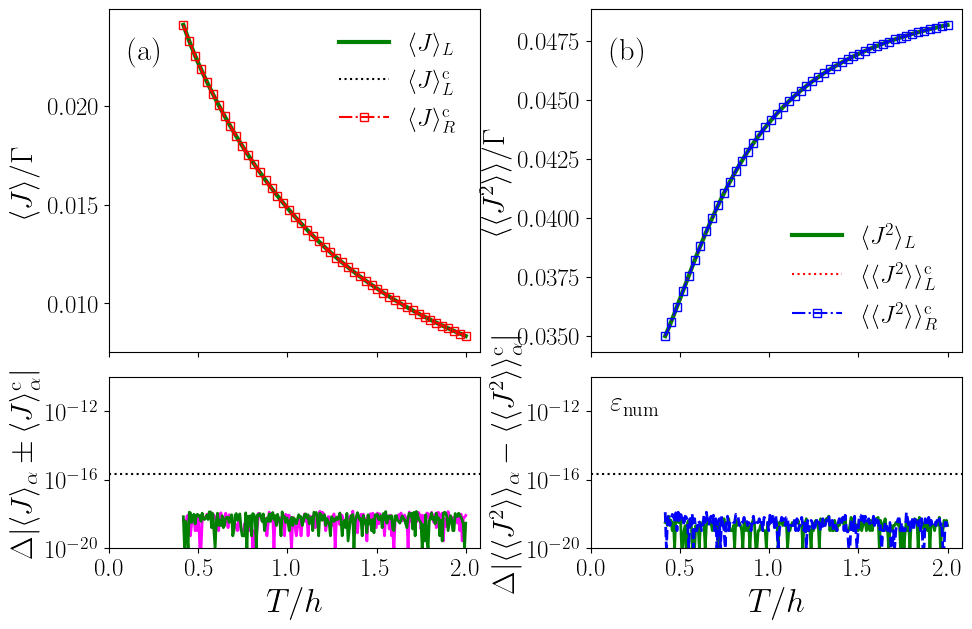

In [41]:
eps = np.finfo(float).eps
floor = 1e-20  # avoids log(0) if the residual is exactly zero

fig, ax = plt.subplots(2, 2, figsize=(11, 7), sharex='col',
                       gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.1, 'wspace': 0.3})

# ---- (a) first moment ----
ax[0, 0].plot(T[60:], I_avg[60:]/Gamma, color='green', lw=3, label=r'$\langle J \rangle_L$')

ax[0, 0].plot(T[60:], I_L[60:]/Gamma, color='black', ms=7, mfc='none', linestyle=':', markevery=5, 
              label=r'$\langle J \rangle^{\rm c}_L$')

ax[0, 0].plot(T[60:], -I_R[60:]/Gamma, 's', color='r', ms=6, mfc='none', linestyle='-.', markevery=5, 
              label=r'$\langle J \rangle^{\rm c}_R$')

res_a = np.abs(I_avg[60:] - I_L[60:])          # check your sign convention, see note below
ax[1, 0].semilogy(T[60:], np.maximum(res_a, floor), color='magenta', lw=2)
res_b = np.abs(I_avg[60:] + I_R[60:])          # check your sign convention, see note below
ax[1, 0].semilogy(T[60:], np.maximum(res_b, floor), color='g', lw=2)

# ---- (b) second moment ----
ax[0, 1].plot(T[60:], I_I[60:]/Gamma, color='green', lw=3, label=r'$\langle J^2 \rangle_L$')
ax[0, 1].plot(T[60:], D_L[60:]/Gamma, color='red', ms=7, mfc='none', markevery=5, linestyle=':',
              label=r'$\langle\langle J^2 \rangle\rangle^{\rm c}_L$')
ax[0, 1].plot(T[60:], D_R[60:]/Gamma, 's', color='b', ms=6, mfc='none', markevery=5, linestyle='-.',
              label=r'$\langle\langle J^2 \rangle\rangle^{\rm c}_R$')
ax[1, 1].semilogy(T[60:], np.maximum(np.abs(I_I[60:] - D_L[60:]), floor), color='g', lw=2, label='L')
ax[1, 1].semilogy(T[60:], np.maximum(np.abs(I_I[60:] - D_R[60:]), floor), color='b', lw=2, ls='--', label='R')

# ---- reference line at machine precision ----
for a in ax[1]:
    a.axhline(eps, color='k', ls=':', lw=1.5)
    a.set_ylim(floor, 1e-10)
ax[1, 1].text(0.05, 0.8, r'$\varepsilon_{\rm num}$', transform=ax[1, 1].transAxes, fontsize=20)

# ---- labels, ticks, panel letters ----
ax[0, 0].set_ylabel(r'$\langle J \rangle/\Gamma$')
ax[0, 1].set_ylabel(r'$\langle\langle J^2 \rangle\rangle/\Gamma$')
ax[1, 0].set_ylabel(r'$\Delta |\langle J \rangle_\alpha \pm \langle J \rangle^{\rm c}_\alpha|$')
ax[1, 1].set_ylabel(r'$\Delta |\langle \langle J^2  \rangle \rangle_\alpha-\langle \langle J^2  \rangle \rangle^{\rm c}_\alpha |$')
for a in ax[1]:
    a.set_xlabel(r'$T/h$')
for a in ax.flat:
    a.tick_params(labelsize=18)
    a.xaxis.label.set_size(24)
    a.yaxis.label.set_size(22)
    a.set_xticks(np.arange(0, 2.1, 0.5))
for a in ax[0]:
    a.legend(fontsize=18, frameon=False)

for a, s in zip(ax[0], ['(a)', '(b)']):
    a.text(0.05, 0.92, s, transform=a.transAxes, fontsize=22, va='top')

fig.align_ylabels(ax[:, 0])
plt.tight_layout(pad=1.5, w_pad=1.5, h_pad=.5);
# fig.savefig('match_LB_IP_differences_v2.pdf', bbox_inches='tight')